In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#Archivo
nombre_archivo = 'TP1_oxi.xlsx'

# Cargar el archivo Excel
datos = pd.read_excel(nombre_archivo)
print(datos.columns.tolist())

# La primera columna es la longitud de onda
onda_col = datos.columns[0]
# Las demás columnas son las muestras
muestras = datos.columns[1:]

['λ (nm)', 'A (Ethanol)', 'A (DOTC)', 'A (DOTC_1 _06)', 'A (DOTC_1 _12)', 'A (DOTC_1 _24)', 'A (DODCI_1 _12)', 'A (DODCI_1 _36)', 'A (DOCI_1 _06)', 'A (DOCI_1 _18)', 'A (DOCI_1 _36)']


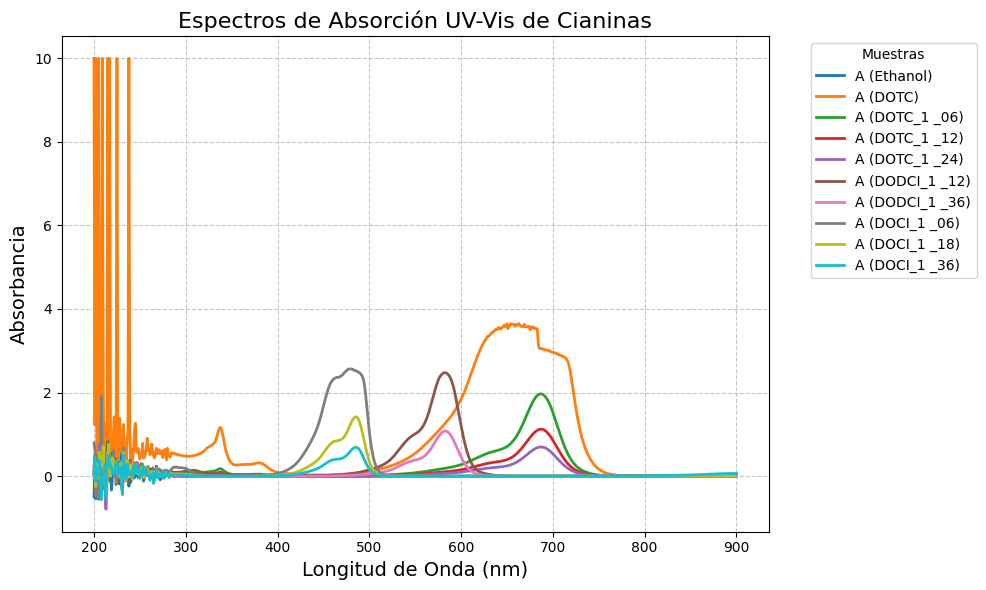

In [3]:
# BLOQUE 2: Gráfico de Espectros UV-Vis
plt.figure(figsize=(10, 6))

# Iterar sobre todas las columnas y graficarlas
for muestra in muestras:
    plt.plot(datos[onda_col], datos[muestra], label=muestra, linewidth=2)

# Formato del gráfico
plt.title('Espectros de Absorción UV-Vis de Cianinas', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend(title='Muestras', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

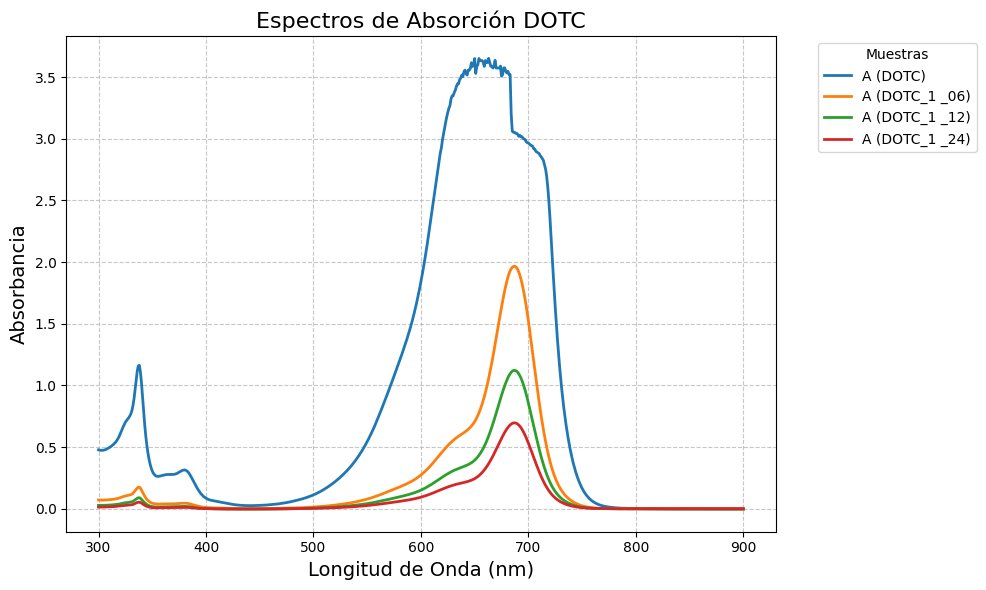

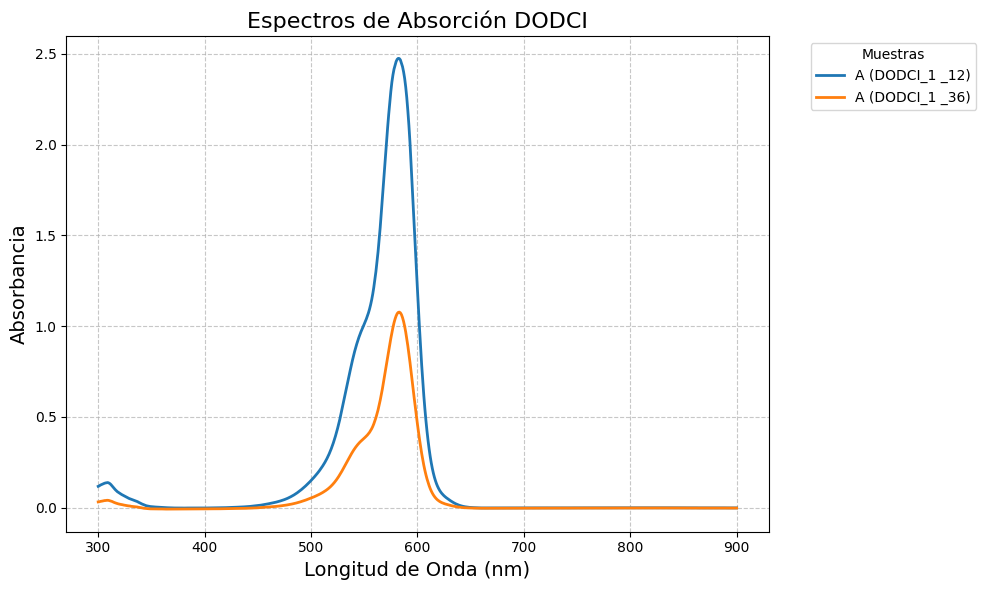

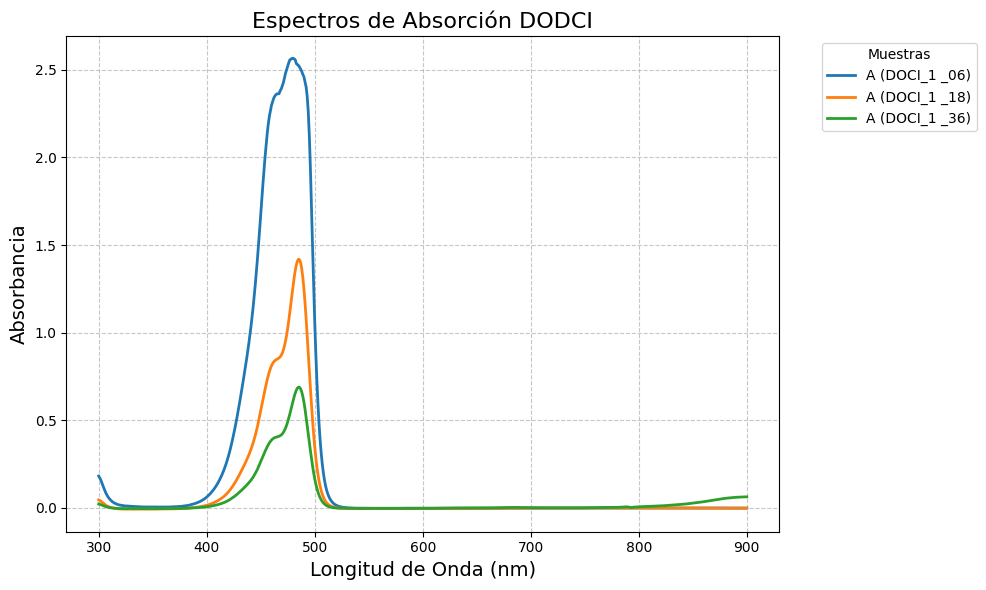

In [4]:
# BLOQUE 3: Datos limpios

datos_1 = datos[(datos['λ (nm)'] >= 300)]
# La primera columna es la longitud de onda
onda_col = datos_1.columns[0]
# Las demás columnas son las muestras
muestras = datos_1.columns[1:]


#PARA LAS DOTC

plt.figure(figsize=(10, 6))

# Iterar
for muestra in muestras[1:5]:
    plt.plot(datos_1[onda_col], datos_1[muestra], label=muestra, linewidth=2)

plt.title('Espectros de Absorción DOTC', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend(title='Muestras', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()


#PARA LAS DODCI

plt.figure(figsize=(10, 6))

# Iterar
for muestra in muestras[5:7]:
    plt.plot(datos_1[onda_col], datos_1[muestra], label=muestra, linewidth=2)

plt.title('Espectros de Absorción DODCI', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend(title='Muestras', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()



#PARA LAS DOCI

plt.figure(figsize=(10, 6))

# Iterar
for muestra in muestras[7:10]:
    plt.plot(datos_1[onda_col], datos_1[muestra], label=muestra, linewidth=2)

plt.title('Espectros de Absorción DODCI', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend(title='Muestras', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

In [5]:
#Búsqueda del pico máximo de absorción
lambdas_max = {}

print("Resultados experimentales (Picos máximos de absorción):")
print("-" * 50)

for muestra in muestras:
    # Encontrar el índice donde la absorbancia es máxima
    indice_max = datos_1[muestra].idxmax() #encuentra el maximo valor y nos da el lugar
    # Encontrar la longitud de onda en ese índice
    l_max = datos_1[onda_col].iloc[indice_max]
    absorbancia_max = datos_1[muestra].iloc[indice_max]

    # Guardar los datos extraídos para el gráfico final
    lambdas_max[muestra] = l_max
    print(f"{muestra}: Lambda_max = {l_max} nm (Absorbancia: {absorbancia_max:.3f})")



Resultados experimentales (Picos máximos de absorción):
--------------------------------------------------
A (Ethanol): Lambda_max = 793 nm (Absorbancia: -0.001)
A (DOTC): Lambda_max = 663 nm (Absorbancia: 3.651)
A (DOTC_1 _06): Lambda_max = 687 nm (Absorbancia: 1.967)
A (DOTC_1 _12): Lambda_max = 687 nm (Absorbancia: 1.122)
A (DOTC_1 _24): Lambda_max = 687 nm (Absorbancia: 0.697)
A (DODCI_1 _12): Lambda_max = 582 nm (Absorbancia: 2.475)
A (DODCI_1 _36): Lambda_max = 583 nm (Absorbancia: 1.077)
A (DOCI_1 _06): Lambda_max = 480 nm (Absorbancia: 2.566)
A (DOCI_1 _18): Lambda_max = 485 nm (Absorbancia: 1.420)
A (DOCI_1 _36): Lambda_max = 485 nm (Absorbancia: 0.690)


DOTC -> Longitud de onda máxima: 683.20 nm | Sigma (Error): 22.42 nm


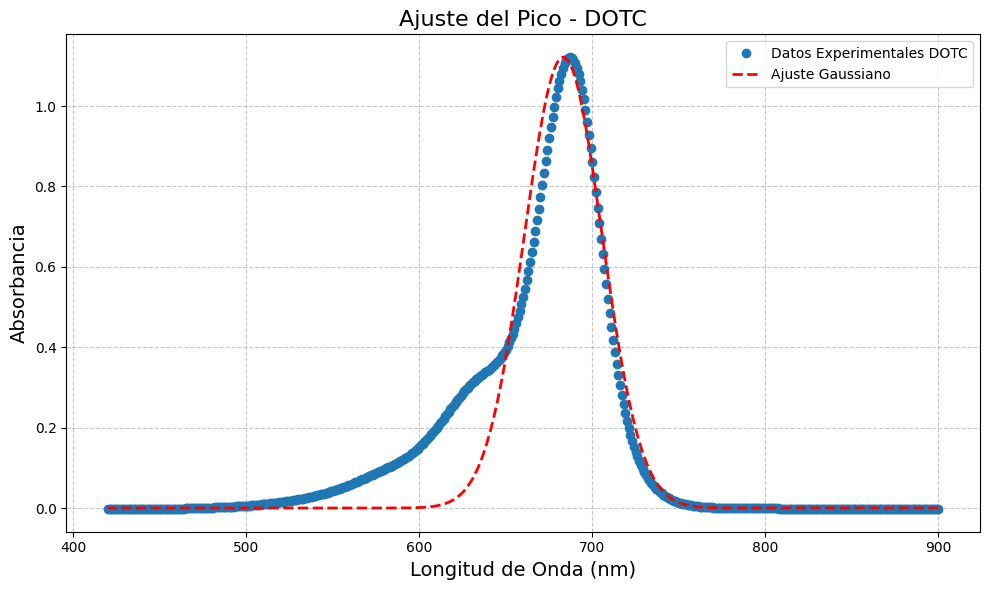

DODCI -> Longitud de onda máxima: 579.13 nm | Sigma (Error): 17.33 nm


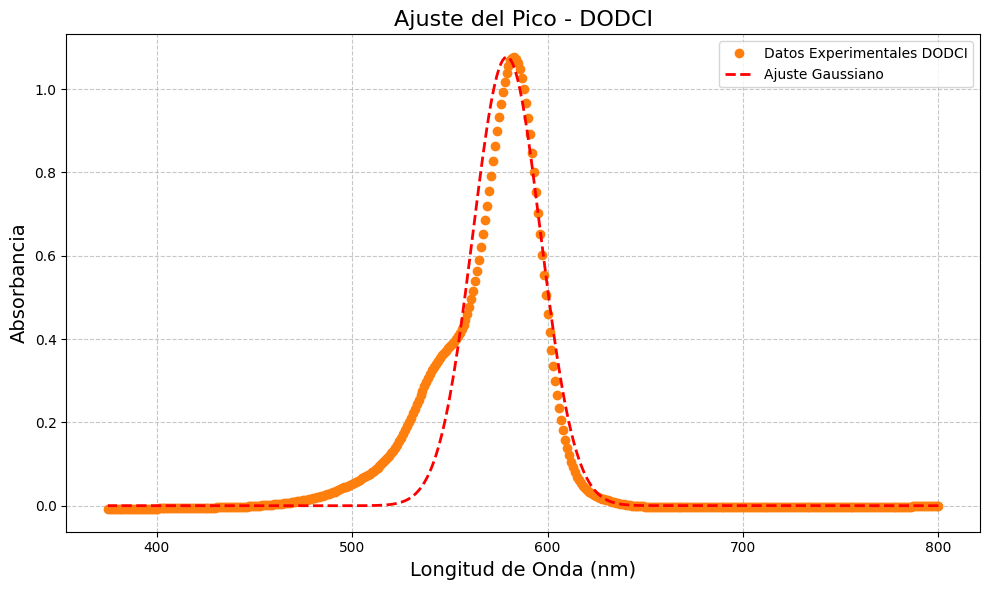

DOCI -> Longitud de onda máxima: 477.02 nm | Sigma (Error): 16.55 nm


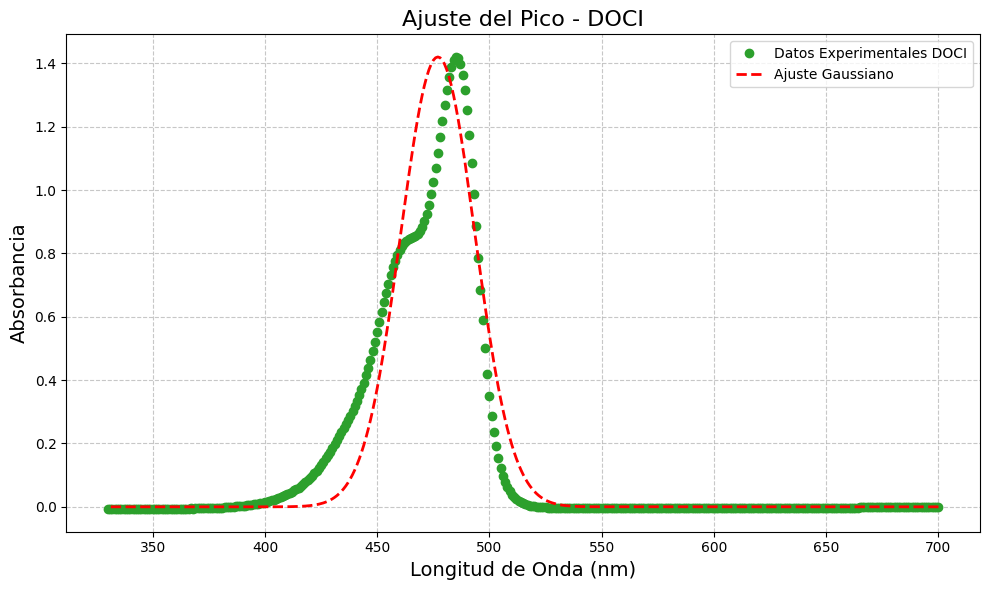

In [6]:
#Ajuste para encontrar la longitu de onda maxima mediante gaussianas

# Definimos una única función gaussiana
def gaussian_function(x, centro, sigma, amplitud):
    return amplitud * np.exp(-((x - centro) ** 2) / (2 * sigma ** 2))


# 1. PARA LAS DOTC (3ra columna de su grupo -> muestras[3])
muestra_dotc = muestras[3]

#RANGO
rango_min_dotc = 420
rango_max_dotc = 900
amplitud_dotc = 1.122  # AMPLITUD

# 1. Filtramos los datos
filtro_dotc = (datos_1[onda_col] >= rango_min_dotc) & (datos_1[onda_col] <= rango_max_dotc)
x_dotc = datos_1[onda_col][filtro_dotc].values
y_dotc = datos_1[muestra_dotc][filtro_dotc].values

# 2. Hacemos el ajuste (damos un valor inicial para el centro y sigma)
# Pasamos la amplitud_dotc como argumento fijo a curve_fit
parametros_dotc, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_dotc), x_dotc, y_dotc, p0=[680, 20])
centro_dotc = parametros_dotc[0]
sigma_dotc = parametros_dotc[1]

print(f"DOTC -> Longitud de onda máxima: {centro_dotc:.2f} nm | Sigma (Error): {sigma_dotc:.2f} nm")

# 3. Graficamos
plt.figure(figsize=(10, 6))
plt.plot(x_dotc, y_dotc, 'o', label='Datos Experimentales DOTC')
plt.plot(x_dotc, gaussian_function(x_dotc, centro_dotc, sigma_dotc, amplitud_dotc), 'r--', label='Ajuste Gaussiano', linewidth=2)
plt.title('Ajuste del Pico - DOTC', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()




# 2. PARA LAS DODCI (2da columna de su grupo -> muestras[6])
muestra_dodci = muestras[6]

#PARAMETROS
rango_min_dodci = 375
rango_max_dodci = 800
amplitud_dodci = 1.077  # AMPLITUD

# 1. Filtramos los datos
filtro_dodci = (datos_1[onda_col] >= rango_min_dodci) & (datos_1[onda_col] <= rango_max_dodci)
x_dodci = datos_1[onda_col][filtro_dodci].values
y_dodci = datos_1[muestra_dodci][filtro_dodci].values

# 2. Hacemos el ajuste
# Pasamos la amplitud_dodci como argumento fijo a curve_fit
parametros_dodci, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_dodci), x_dodci, y_dodci, p0=[580, 20])
centro_dodci = parametros_dodci[0]
sigma_dodci = parametros_dodci[1]

print(f"DODCI -> Longitud de onda máxima: {centro_dodci:.2f} nm | Sigma (Error): {sigma_dodci:.2f} nm")

# 3. Graficamos
plt.figure(figsize=(10, 6))
plt.plot(x_dodci, y_dodci, 'o', color='tab:orange', label='Datos Experimentales DODCI')
plt.plot(x_dodci, gaussian_function(x_dodci, centro_dodci, sigma_dodci, amplitud_dodci), 'r--', label='Ajuste Gaussiano', linewidth=2)
plt.title('Ajuste del Pico - DODCI', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



# 3. PARA LAS DOCI (2da columna de su grupo -> muestras[8])
muestra_doci = muestras[8]

#PARAMETROS
rango_min_doci = 330
rango_max_doci = 700
amplitud_doci = 1.420  # AMPLITUD

# 1. Filtramos los datos para el rango elegido
filtro_doci = (datos_1[onda_col] >= rango_min_doci) & (datos_1[onda_col] <= rango_max_doci)
x_doci = datos_1[onda_col][filtro_doci].values
y_doci = datos_1[muestra_doci][filtro_doci].values

# 2. Hacemos el ajuste
# Pasamos la amplitud_doci como argumento fijo a curve_fit
parametros_doci, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_doci), x_doci, y_doci, p0=[480, 20])
centro_doci = parametros_doci[0]
sigma_doci = parametros_doci[1]

print(f"DOCI -> Longitud de onda máxima: {centro_doci:.2f} nm | Sigma (Error): {sigma_doci:.2f} nm")

# 3. Graficamos
plt.figure(figsize=(10, 6))
plt.plot(x_doci, y_doci, 'o', color='tab:green', label='Datos Experimentales DOCI')
plt.plot(x_doci, gaussian_function(x_doci, centro_doci, sigma_doci, amplitud_doci), 'r--', label='Ajuste Gaussiano', linewidth=2)
plt.title('Ajuste del Pico - DOCI', fontsize=16)
plt.xlabel('Longitud de Onda (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

<>:58: SyntaxWarning: invalid escape sequence '\l'
<>:120: SyntaxWarning: invalid escape sequence '\l'
<>:58: SyntaxWarning: invalid escape sequence '\l'
<>:120: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_749/3617060216.py:58: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\lambda_{max}$ (nm)', fontsize=14)
/tmp/ipykernel_749/3617060216.py:120: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\lambda_{max}$ (nm)', fontsize=14)


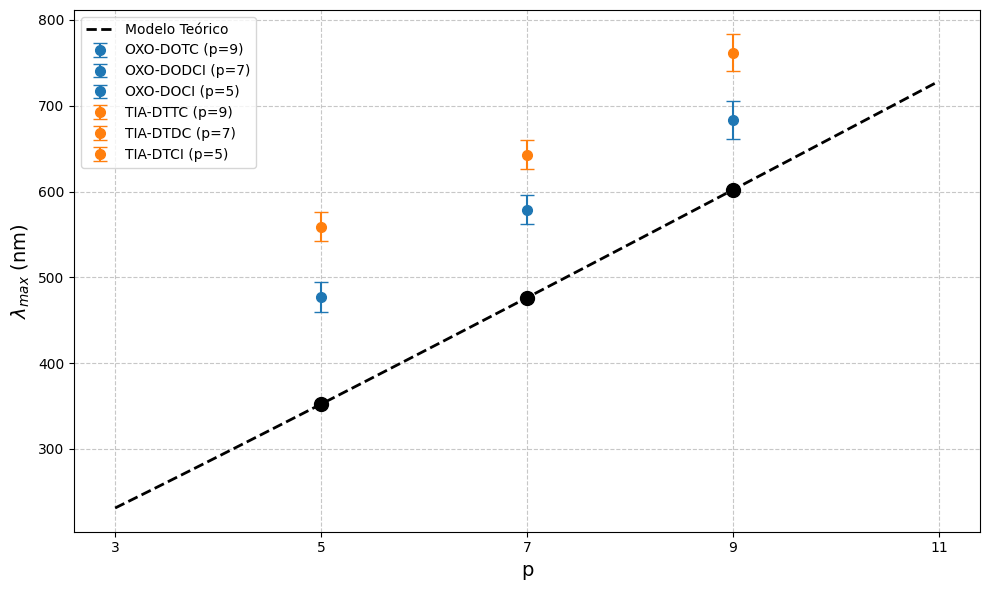

El parámetro alfa óptimo para OXO es: 2.959 ± 0.091


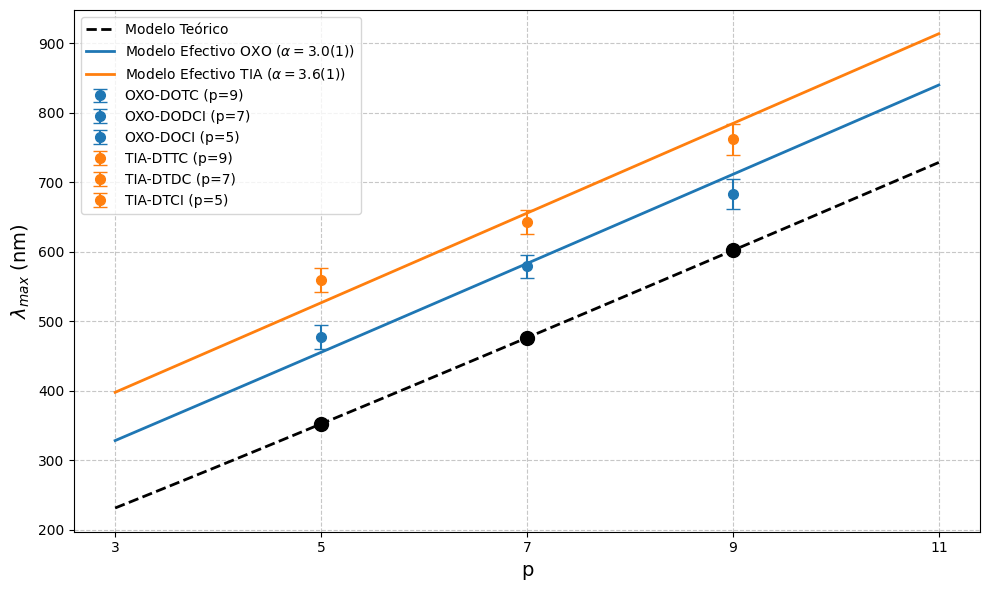

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ==============================================================================
# Datos de entrada
# ==============================================================================
p_exp = np.array([5, 7, 9])

# Datos OXO (para el ajuste)
lambda_exp_oxo = np.array([477, 579, 683])
sigma_exp_oxo = np.array([17, 17, 22])

# ==============================================================================
# PARTE 1: Comparación Modelo Teórico Original vs Resultados Experimentales
# ==============================================================================

# 1. Definir la función del modelo teórico (Pozo de potencial original)
def calcular_lambda_teorico(p):
    # Constantes físicas
    h = 6.626e-34      # Constante de Planck (J*s)
    m = 9.109e-31      # Masa del electrón (kg)
    c = 3.0e8          # Velocidad de la luz (m/s)
    d = 0.14e-9        # Distancia interatómica C-C (metros)

    # Ecuación del pozo de potencial unidimensional
    numerador = 8 * m * c * ((p + 2) * d)**2
    denominador = h * (p + 4)
    lambda_metros = numerador / denominador

    return lambda_metros * 1e9 # a nanómetros

# 2. Generar datos teóricos para graficar la línea
p_teoricos = np.linspace(3, 11, 50)
lambda_teoricos = [calcular_lambda_teorico(p) for p in p_teoricos]

# 3. Graficar Parte 1
plt.figure(figsize=(10, 6))

plt.plot(p_teoricos, lambda_teoricos, 'k--', label='Modelo Teórico', linewidth=2)

# Puntos DEL MODELO TEORICO (Agrupados en una línea para limpieza)
p_valores = [5, 7, 9]
lambda_valores = [calcular_lambda_teorico(p) for p in p_valores]
plt.scatter(x=p_valores, y=lambda_valores, c='black', s=100, zorder=5)

# Puntos experimentales OXO
plt.errorbar(x=9, y=683, yerr=22, fmt='o', color='tab:blue', label="OXO-DOTC (p=9)", capsize=5, markersize=7)
plt.errorbar(x=7, y=579, yerr=17, fmt='o', color='tab:blue', label="OXO-DODCI (p=7)", capsize=5, markersize=7)
plt.errorbar(x=5, y=477, yerr=17, fmt='o', color='tab:blue', label="OXO-DOCI (p=5)", capsize=5, markersize=7)

# Puntos experimentales TIA
plt.errorbar(x=9, y=762, yerr=22, fmt='o', color='tab:orange', label="TIA-DTTC (p=9)", capsize=5, markersize=7)
plt.errorbar(x=7, y=643, yerr=17, fmt='o', color='tab:orange', label="TIA-DTDC (p=7)", capsize=5, markersize=7)
plt.errorbar(x=5, y=559, yerr=17, fmt='o', color='tab:orange', label="TIA-DTCI (p=5)", capsize=5, markersize=7)

plt.xlabel('p', fontsize=14)
plt.ylabel('$\lambda_{max}$ (nm)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(3, 12, 2))
plt.tight_layout()
plt.show()

# ==============================================================================
# PARTE 2: Ajuste del Modelo Modificando la Longitud Efectiva L = (p + alfa)*d
# ==============================================================================

# 1. Definir la nueva función para el ajuste
def funcion_ajuste_alfa(p, alfa):
    h = 6.626e-34
    m = 9.109e-31
    c = 3.0e8
    d = 0.14e-9

    numerador = 8 * m * c * ((p + alfa) * d)**2
    denominador = h * (p + 4)
    lambda_metros = numerador / denominador

    return lambda_metros * 1e9

# 2. Ajustar modelo para las OXO
parametros_optimos, covarianza = curve_fit(funcion_ajuste_alfa, p_exp, lambda_exp_oxo, p0=[3.0], sigma=sigma_exp_oxo, absolute_sigma=True)
alfa_optimo_oxo = parametros_optimos[0]
# Calcular el error estándar (incertidumbre) tomando la raíz cuadrada de la diagonal de la covarianza
error_alfa_oxo = np.sqrt(covarianza[0, 0])

print(f"El parámetro alfa óptimo para OXO es: {alfa_optimo_oxo:.3f} ± {error_alfa_oxo:.3f}")

# 3. Definir el alfa de las TIO (Calculado previamente)
alfa_optimo_tio = 3.56

# 4. Generar datos teóricos para las dos curvas ajustadas
lambda_ajustados_oxo = funcion_ajuste_alfa(p_teoricos, alfa_optimo_oxo)
lambda_ajustados_tio = funcion_ajuste_alfa(p_teoricos, alfa_optimo_tio)

# 5. Graficar todo final
plt.figure(figsize=(10, 6))

# Curvas de los Modelos
plt.plot(p_teoricos, lambda_teoricos, 'k--', label='Modelo Teórico', linewidth=2)
plt.plot(p_teoricos, lambda_ajustados_oxo, color='tab:blue', linestyle='-', label=f'Modelo Efectivo OXO ($\\alpha = 3.0(1)$)', linewidth=2)
plt.plot(p_teoricos, lambda_ajustados_tio, color='tab:orange', linestyle='-', label=f'Modelo Efectivo TIA ($\\alpha = 3.6(1)$)', linewidth=2)

# Puntos DEL MODELO TEORICO
plt.scatter(x=p_valores, y=lambda_valores, c='black', s=100, zorder=5)

# Puntos experimentales OXO
plt.errorbar(x=9, y=683, yerr=22, fmt='o', color='tab:blue', label="OXO-DOTC (p=9)", capsize=5, markersize=7)
plt.errorbar(x=7, y=579, yerr=17, fmt='o', color='tab:blue', label="OXO-DODCI (p=7)", capsize=5, markersize=7)
plt.errorbar(x=5, y=477, yerr=17, fmt='o', color='tab:blue', label="OXO-DOCI (p=5)", capsize=5, markersize=7)

# Puntos experimentales TIO
plt.errorbar(x=9, y=762, yerr=22, fmt='o', color='tab:orange', label="TIA-DTTC (p=9)", capsize=5, markersize=7)
plt.errorbar(x=7, y=643, yerr=17, fmt='o', color='tab:orange', label="TIA-DTDC (p=7)", capsize=5, markersize=7)
plt.errorbar(x=5, y=559, yerr=17, fmt='o', color='tab:orange', label="TIA-DTCI (p=5)", capsize=5, markersize=7)

# Formato del gráfico
plt.xlabel('p', fontsize=14)
plt.ylabel('$\lambda_{max}$ (nm)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(3, 12, 2))

plt.tight_layout()
plt.show()

DOTC -> Longitud de onda máxima: 683.20 nm | Sigma (Error): 22.42 nm
DODCI -> Longitud de onda máxima: 579.13 nm | Sigma (Error): 17.33 nm
DOCI -> Longitud de onda máxima: 477.02 nm | Sigma (Error): 16.55 nm


<>:80: SyntaxWarning: invalid escape sequence '\l'
<>:80: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_749/1317743875.py:80: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)', fontsize=14)


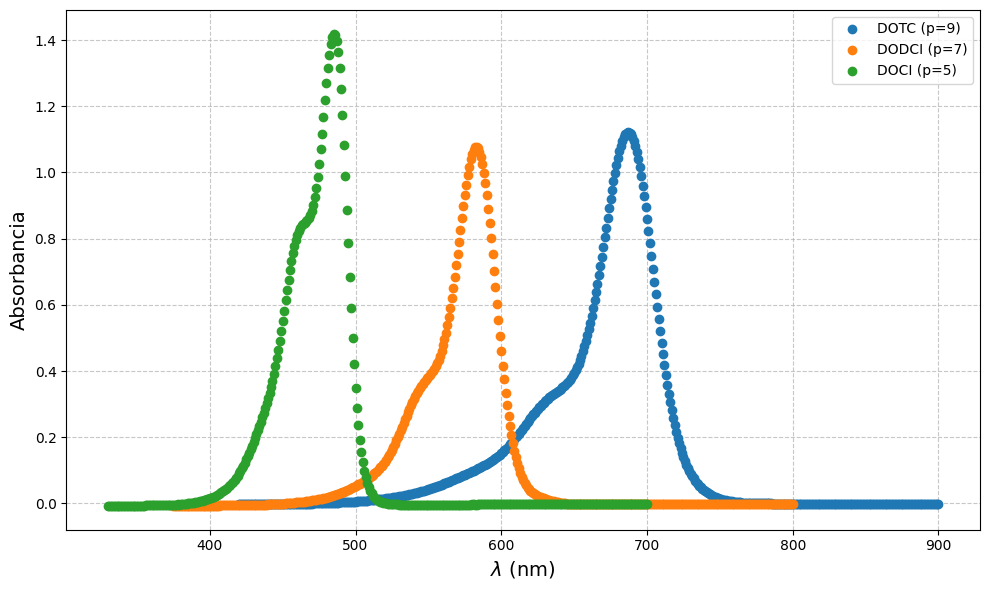

In [8]:
#Grafico de todos los espectros con la Absorvancia cercana a 1:
#Ajuste para encontrar la longitu de onda maxima mediante gaussianas

# Definimos una única función gaussiana
def gaussian_function(x, centro, sigma, amplitud):
    return amplitud * np.exp(-((x - centro) ** 2) / (2 * sigma ** 2))


# 1. PARA LAS DOTC (3ra columna de su grupo -> muestras[3])
muestra_dotc = muestras[3]

#RANGO
rango_min_dotc = 420
rango_max_dotc = 900
amplitud_dotc = 1.122  # AMPLITUD

# 1. Filtramos los datos
filtro_dotc = (datos_1[onda_col] >= rango_min_dotc) & (datos_1[onda_col] <= rango_max_dotc)
x_dotc = datos_1[onda_col][filtro_dotc].values
y_dotc = datos_1[muestra_dotc][filtro_dotc].values

# 2. Hacemos el ajuste (damos un valor inicial para el centro y sigma)
# Pasamos la amplitud_dotc como argumento fijo a curve_fit
parametros_dotc, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_dotc), x_dotc, y_dotc, p0=[680, 20])
centro_dotc = parametros_dotc[0]
sigma_dotc = parametros_dotc[1]

print(f"DOTC -> Longitud de onda máxima: {centro_dotc:.2f} nm | Sigma (Error): {sigma_dotc:.2f} nm")


# 2. PARA LAS DODCI (2da columna de su grupo -> muestras[6])
muestra_dodci = muestras[6]

#PARAMETROS
rango_min_dodci = 375
rango_max_dodci = 800
amplitud_dodci = 1.077  # AMPLITUD

# 1. Filtramos los datos
filtro_dodci = (datos_1[onda_col] >= rango_min_dodci) & (datos_1[onda_col] <= rango_max_dodci)
x_dodci = datos_1[onda_col][filtro_dodci].values
y_dodci = datos_1[muestra_dodci][filtro_dodci].values

# 2. Hacemos el ajuste
# Pasamos la amplitud_dodci como argumento fijo a curve_fit
parametros_dodci, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_dodci), x_dodci, y_dodci, p0=[580, 20])
centro_dodci = parametros_dodci[0]
sigma_dodci = parametros_dodci[1]

print(f"DODCI -> Longitud de onda máxima: {centro_dodci:.2f} nm | Sigma (Error): {sigma_dodci:.2f} nm")

# 3. PARA LAS DOCI (2da columna de su grupo -> muestras[8])
muestra_doci = muestras[8]

#PARAMETROS
rango_min_doci = 330
rango_max_doci = 700
amplitud_doci = 1.420  # AMPLITUD

# 1. Filtramos los datos para el rango elegido
filtro_doci = (datos_1[onda_col] >= rango_min_doci) & (datos_1[onda_col] <= rango_max_doci)
x_doci = datos_1[onda_col][filtro_doci].values
y_doci = datos_1[muestra_doci][filtro_doci].values

# 2. Hacemos el ajuste
# Pasamos la amplitud_doci como argumento fijo a curve_fit
parametros_doci, _ = curve_fit(lambda x, centro, sigma: gaussian_function(x, centro, sigma, amplitud_doci), x_doci, y_doci, p0=[480, 20])
centro_doci = parametros_doci[0]
sigma_doci = parametros_doci[1]

print(f"DOCI -> Longitud de onda máxima: {centro_doci:.2f} nm | Sigma (Error): {sigma_doci:.2f} nm")

# 3. Graficamos

plt.figure(figsize=(10, 6))
plt.plot(x_dotc, y_dotc, 'o', label='DOTC (p=9)')
plt.plot(x_dodci, y_dodci, 'o', color='tab:orange', label='DODCI (p=7)')
plt.plot(x_doci, y_doci, 'o', color='tab:green', label='DOCI (p=5)')
#plt.title('Ajuste del Pico - DOTC', fontsize=16)
plt.xlabel('$\lambda$ (nm)', fontsize=14)
plt.ylabel('Absorbancia', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

In [9]:
import pandas as pd

# ==============================================================================
# Parámetros iniciales
# ==============================================================================
d = 0.14  # Distancia interatómica promedio C-C en nanómetros (nm)

# Datos de la familia OXO
alfa_oxo = 2.96
err_alfa_oxo = 0.091
nombres_oxo = ['DOCI', 'DODCI', 'DOTC']
p_oxo = [5, 7, 9]

# Datos de la familia TIO
alfa_tio = 3.649
err_alfa_tio = 0.100
nombres_tio = ['DTCI', 'DTDC', 'DTTC']
p_tio = [5, 7, 9]

# ==============================================================================
# Función de cálculo
# ==============================================================================
def calcular_pozo(nombres, p_valores, alfa, err_alfa, familia):
    datos = []
    for nombre, p in zip(nombres, p_valores):
        # 1. Longitud teórica original L = (p + 2) * d
        l_orig = (p + 2) * d

        # 2. Longitud efectiva ajustada L = (p + alfa) * d
        l_eff = (p + alfa) * d

        # 3. Propagación del error: Error(L) = Error(alfa) * d
        err_l_eff = err_alfa * d

        # 4. Diferencia porcentual respecto al original
        dif_porcentual = ((l_eff - l_orig) / l_orig) * 100

        datos.append({
            'Familia': familia,
            'Cianina': nombre,
            'p': p,
            'L_orig (nm)': f"{l_orig:.4f}",
            'L_eff (nm)': f"{l_eff:.4f} ± {err_l_eff:.4f}",
            'Dif (%)': f"{dif_porcentual:.1f}%"
        })
    return datos

# ==============================================================================
# Ejecución y visualización
# ==============================================================================
resultados_totales = calcular_pozo(nombres_oxo, p_oxo, alfa_oxo, err_alfa_oxo, 'OXO') + \
                     calcular_pozo(nombres_tio, p_tio, alfa_tio, err_alfa_tio, 'TIO')

df_resultados = pd.DataFrame(resultados_totales)

print("COMPARACIÓN DE LONGITUDES DEL POZO DE POTENCIAL")
print("-" * 75)
print(df_resultados.to_string(index=False))
print("-" * 75)

COMPARACIÓN DE LONGITUDES DEL POZO DE POTENCIAL
---------------------------------------------------------------------------
Familia Cianina  p L_orig (nm)      L_eff (nm) Dif (%)
    OXO    DOCI  5      0.9800 1.1144 ± 0.0127   13.7%
    OXO   DODCI  7      1.2600 1.3944 ± 0.0127   10.7%
    OXO    DOTC  9      1.5400 1.6744 ± 0.0127    8.7%
    TIO    DTCI  5      0.9800 1.2109 ± 0.0140   23.6%
    TIO    DTDC  7      1.2600 1.4909 ± 0.0140   18.3%
    TIO    DTTC  9      1.5400 1.7709 ± 0.0140   15.0%
---------------------------------------------------------------------------
